# Fábrica de Corpus · Vai de Primeira

Ferramenta que transforma documentos públicos sobre **Carteira de Identidade Nacional (CIN), renovação da CNH, Cadastro Único e BPC** em três corpora prontos para o ajuste fino de um modelo de linguagem pequeno (SLM).

**Cidadã atendida (persona):** Dona Francisca, 67 anos, mora na zona rural de Itapeva (SP), lê com dificuldade e já perdeu duas viagens ao posto de atendimento por falta de um documento.
**Problema:** a informação sobre o que levar, onde ir e se o serviço é gratuito está espalhada em páginas oficiais longas e técnicas.
**ODS:** 10 (redução das desigualdades: orientação acessível para quem tem pouca escolaridade), 9 (acesso a tecnologias de informação no serviço público) e 4 (letramento digital).

**Integrantes:** Pedro Iavarone Custódio (RM567638) · Rodrigo Ferreira Nery (RM568246)

Etapas: ingestão → extração → limpeza → normalização → anonimização → segmentação → geração dos três corpora → relatório de qualidade → interface.

## 0. Preparação
No Google Colab, a célula abaixo baixa o repositório e instala as bibliotecas. Rodando localmente, ela só ajusta a pasta.

In [1]:
import os, sys
from pathlib import Path

if "google.colab" in sys.modules:
    !git clone -q https://github.com/PedroIavarone/vai-de-primeira.git
    %cd vai-de-primeira/pln
    !pip install -q -r requirements.txt
    !python -m spacy download -q pt_core_news_md
    try:
        from google.colab import userdata
        os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")  # opcional: sem chave, usa o cache
    except Exception:
        pass

PASTA = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd() / "pln"
sys.path.insert(0, str(PASTA / "src"))
import fabrica_corpus as fc
import gerar_corpus as gc
gc.carregar_env()
print("pasta do módulo:", PASTA)
print("chave do Groq:", "configurada" if os.getenv("GROQ_API_KEY") else "ausente (usa o cache de pln/cache/)")

pasta do módulo: /Users/pedroiavarone/Downloads/GS/vai-de-primeira/pln
chave do Groq: configurada


## 1. Ingestão e 2. extração
Cinco documentos oficiais, um em cada formato aceito (PDF, DOCX, TXT e HTML), mais um texto colado. A origem e o link de cada um estão em `entrada/fontes.csv`.

| Formato | Biblioteca |
|---|---|
| PDF | pdfplumber (texto por página, para achar cabeçalhos e rodapés) |
| DOCX | python-docx (parágrafos, títulos, listas e tabelas) |
| TXT | detecção de codificação (UTF-8 ou charset-normalizer) |
| HTML | BeautifulSoup, só com o conteúdo principal da página |

In [2]:
import csv
from IPython.display import Markdown, display

with open(PASTA / "entrada" / "fontes.csv", encoding="utf-8") as f:
    fontes = list(csv.DictReader(f))
display(Markdown("\n".join(["| arquivo | órgão | link |", "|---|---|---|"] +
                            [f"| {l['arquivo']} | {l['orgao']} | {l['url']} |" for l in fontes])))

arquivos = sorted(p for p in (PASTA / "entrada").iterdir() if p.suffix.lower() in fc.FORMATOS)
documentos = [fc.ler_caminho(p) for p in arquivos]
documentos.append(fc.ler_texto_colado(gc.EXEMPLO_COLADO, "texto_colado_ficticio"))
for d in documentos:
    print(f"{d.fonte:40} {d.formato:7} {len(d.paginas):>3} página(s)  {fc.contar_tokens(d.bruto):>6} tokens extraídos")

| arquivo | órgão | link |
|---|---|---|
| bpc_perguntas_mds.pdf | Ministério do Desenvolvimento e Assistência Social | https://www.mds.gov.br/webarquivos/assistencia_social/bpc/Perguntas%20Frequentes%20BPC.pdf |
| cnh_renovacao_detran_sp_duvidas.html | Detran-SP | http://mobile.detran.sp.gov.br/wps/wcm/connect/portaldetran/detran/duvidasFrequentes/SA-CNH-Habilitacao/SA-Renovacao/ |
| cin_govbr_perguntas.html | Ministério da Gestão e da Inovação em Serviços Públicos | https://www.gov.br/gestao/pt-br/identidade-nacional |
| cin_poupatempo_sp.docx | Governo do Estado de São Paulo (Poupatempo) | https://www.poupatempo.sp.gov.br/carta/D97C3844-A2D9-4C9E-B364-CB4FEB26A1FB |
| cadunico_inscrever_govbr.txt | Ministério do Desenvolvimento e Assistência Social | https://www.gov.br/pt-br/servicos/inscrever-se-no-cadastro-unico-para-programas-sociais-do-governo-federal |

bpc_perguntas_mds.pdf                    pdf      14 página(s)    7725 tokens extraídos
cadunico_inscrever_govbr.txt             txt       1 página(s)    2990 tokens extraídos
cin_govbr_perguntas.html                 html      1 página(s)    1489 tokens extraídos
cin_poupatempo_sp.docx                   docx      1 página(s)    3473 tokens extraídos
cnh_renovacao_detran_sp_duvidas.html     html      1 página(s)    8707 tokens extraídos
texto_colado_ficticio                    colado    1 página(s)      95 tokens extraídos


In [3]:
pdf = next(d for d in documentos if d.formato == "pdf")
print("Início do PDF como saiu da extração (repare no título com letras espaçadas e no cabeçalho de cada página):\n")
print(pdf.paginas[0][:400], "\n...\n", pdf.paginas[5][:300])

Início do PDF como saiu da extração (repare no título com letras espaçadas e no cabeçalho de cada página):

Benefício de Prestação
Continuada
P E R G U N T A S
F R E Q U E N T E S
Ministério da Cidadania
F e v e r e i r o / 2 0 2 1
Secretaria Nacional de Assistência Social
Departamento de Benefícios Assistenciais 
...
 BENEFÍCIO DE PRESTAÇÃO CONTINUADA - PERGUNTAS FREQUENTES
23. SE O REQUERENTE NÃO TIVER DOCUMENTOS, ELE PODE DAR ENTRADA NO BPC?
Sim, desde que a informação consiga ser confirmada pelo INSS por meio de consultas a
outros banco de dados.
Mesmo que isso ocorra, o INSS pode pedir, a qualquer tempo, os d


## 3. Limpeza e 4. normalização
**Limpeza:** remove cabeçalhos e rodapés que se repetem em pelo menos metade das páginas, números de página, URLs soltas (no meio da frase a URL vira só o domínio, como `gov.br`), caracteres invisíveis e de controle, marcadores estranhos, letras espaçadas (`P E R G U N T A S` → `PERGUNTAS`), palavras quebradas por hífen no fim da linha e linhas repetidas de menu. No PDF, junta as linhas que continuam a mesma frase.

**Normalização:** UTF-8 em NFC, espaços e quebras de linha padronizados e aspas retas. **Acentos, pontuação e maiúsculas são mantidos. Não removemos stopwords nem fazemos stemming**, porque o modelo de linguagem precisa do texto natural.

In [4]:
for d in documentos:
    d.limpo = fc.normalizar(fc.limpar(d))
    print(f"{d.fonte:40} {d.log['limpeza']}")
print("\nPDF depois da limpeza e normalização:\n")
print(pdf.limpo[:900])

bpc_perguntas_mds.pdf                    {'cabecalho_rodape': 26, 'numero_pagina': 1, 'letras_espacadas': 4, 'url_no_texto': 1, 'hifenizacao': 1, 'palavra_duplicada': 0}
cadunico_inscrever_govbr.txt             {'letras_espacadas': 0, 'url_no_texto': 0, 'hifenizacao': 0, 'palavra_duplicada': 0, 'linha_repetida': 2}
cin_govbr_perguntas.html                 {'letras_espacadas': 0, 'url_no_texto': 1, 'hifenizacao': 0, 'palavra_duplicada': 0}
cin_poupatempo_sp.docx                   {'letras_espacadas': 0, 'url_no_texto': 0, 'hifenizacao': 0, 'palavra_duplicada': 0, 'linha_repetida': 4}
cnh_renovacao_detran_sp_duvidas.html     {'letras_espacadas': 0, 'url_no_texto': 2, 'hifenizacao': 0, 'palavra_duplicada': 0}
texto_colado_ficticio                    {'letras_espacadas': 0, 'url_no_texto': 0, 'hifenizacao': 0, 'palavra_duplicada': 0}

PDF depois da limpeza e normalização:

Benefício de Prestação
Continuada
PERGUNTAS
FREQUENTES
Ministério da Cidadania
Fevereiro / 2021
Secretaria Nacional de

## 5. Anonimização
Antes de gerar qualquer corpus, mascaramos:
- **CPF** (com pontuação, ou 11 dígitos com dígito verificador válido) → `[CPF]`
- **e-mail** → `[EMAIL]`
- **telefone** com DDD ou no formato 9999-9999 → `[TELEFONE]`. Números de atendimento público (135, 121, 0800) ficam, porque são informação útil e não são dados pessoais.
- **nomes de pessoas** com o reconhecedor de entidades do spaCy (`pt_core_news_md`), com regras para não mascarar nomes de órgãos, documentos e programas → `[NOME]`

Os documentos oficiais quase não têm dados pessoais, então o exemplo abaixo usa um **texto colado fictício**.

In [5]:
for d in documentos:
    d.texto, d.log["anonimizacao"] = fc.anonimizar(d.limpo)
colado = documentos[-1]
print("ANTES :", colado.limpo)
print("DEPOIS:", colado.texto)
print("\nDados mascarados por documento:")
for d in documentos:
    print(f"  {d.fonte:40} {d.log['anonimizacao'] or 'nenhum'}")

ANTES : Relato de atendimento: a Sra. Francisca Alves de Oliveira, CPF 529.982.247-25, procurou o CRAS acompanhada do filho Joaquim Pereira. Contato: (15) 99812-3456 ou francisca.oliveira@email.com. Para dúvidas sobre o BPC, ligue 135. Dados fictícios, criados para demonstrar a anonimização.
DEPOIS: Relato de atendimento: a [NOME], CPF [CPF], procurou o CRAS acompanhada do filho [NOME]. Contato: [TELEFONE] ou [EMAIL]. Para dúvidas sobre o BPC, ligue 135. Dados fictícios, criados para demonstrar a anonimização.

Dados mascarados por documento:
  bpc_perguntas_mds.pdf                    nenhum
  cadunico_inscrever_govbr.txt             nenhum
  cin_govbr_perguntas.html                 nenhum
  cin_poupatempo_sp.docx                   nenhum
  cnh_renovacao_detran_sp_duvidas.html     nenhum
  texto_colado_ficticio                    {'EMAIL': 1, 'CPF': 1, 'TELEFONE': 1, 'NOME': 2}


## 6. Segmentação
Trechos de **256 a 512 tokens** (tokenizador `cl100k_base` do tiktoken), sempre cortando entre parágrafos ou no fim de uma frase. Uma programação dinâmica escolhe os cortes que deixam todos os trechos no intervalo e perto de 400 tokens. O texto colado fictício só serve de demonstração e não entra nos corpora.

61 trechos · mín. 337 · máx. 511 · média 387 tokens · 0 duplicatas removidas


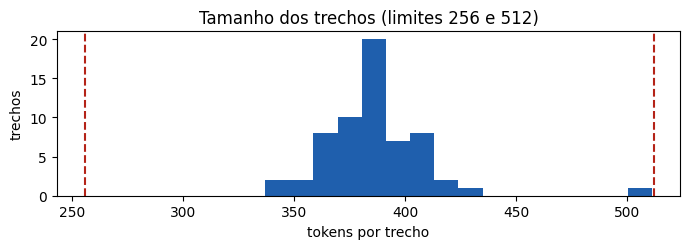

In [6]:
import matplotlib.pyplot as plt

oficiais = [d for d in documentos if d.formato != "colado"]
corpus_texto, duplicatas = fc.corpus_texto(oficiais)
tamanhos = [fc.contar_tokens(t["text"]) for t in corpus_texto]
print(f"{len(corpus_texto)} trechos · mín. {min(tamanhos)} · máx. {max(tamanhos)} · média {sum(tamanhos)/len(tamanhos):.0f} tokens · {duplicatas} duplicatas removidas")
plt.figure(figsize=(7, 2.6))
plt.hist(tamanhos, bins=16, color="#1F5FAD")
plt.axvline(256, color="#B42318", ls="--"); plt.axvline(512, color="#B42318", ls="--")
plt.xlabel("tokens por trecho"); plt.ylabel("trechos"); plt.title("Tamanho dos trechos (limites 256 e 512)")
plt.tight_layout(); plt.show()

## 7. Geração dos três corpora
- **Texto puro:** os trechos da segmentação.
- **Perguntas e respostas:** o modelo `openai/gpt-oss-120b` (Groq, temperatura 0,2) cria de 2 a 3 pares por trecho. Cada resposta traz uma **evidência copiada do trecho**; se a evidência não estiver no trecho, o par é descartado. Isso garante que a resposta está apoiada no documento.
- **Conversacional:** 26 diálogos de orientação (2 trocas, também com evidência) e 12 diálogos de **recusa** de assuntos fora do tema, encaminhando ao profissional ou órgão certo (UBS, Defensoria Pública, Procon, Receita Federal...).
- **Revisão humana:** uma amostra de 20% de cada corpus gerado é revisada pela equipe em `revisao/revisao.csv` (fiel ou não, e a correção). As correções são aplicadas antes de salvar.

As respostas do modelo ficam em cache (`cache/geracao.json`), então o notebook roda do início ao fim mesmo sem a chave. Os prompts completos estão em `src/geracao.py` e em `saida/relatorio_qualidade.json`.

In [7]:
relatorio = gc.executar(None, PASTA / "saida", documentos=[fc.ler_caminho(p) for p in arquivos])
print("\nRevisão humana:", relatorio["revisao_humana"])
print("Pares descartados por falta de evidência:", relatorio["corpus_qa"].get("rejeitados_sem_evidencia"))
print("Diálogos de recusa:", relatorio["corpus_chat"]["recusas"])

bpc_perguntas_mds.pdf                    pdf     14 pág.    7088 tokens
cadunico_inscrever_govbr.txt             txt      1 pág.    2946 tokens


cin_govbr_perguntas.html                 html     1 pág.    1475 tokens


cin_poupatempo_sp.docx                   docx     1 pág.    3440 tokens


cnh_renovacao_detran_sp_duvidas.html     html     1 pág.    8690 tokens


  perguntas e respostas: 10/61 trechos, 27 pares
  perguntas e respostas: 20/61 trechos, 55 pares


  perguntas e respostas: 30/61 trechos, 83 pares
  perguntas e respostas: 40/61 trechos, 112 pares


  perguntas e respostas: 50/61 trechos, 140 pares
  perguntas e respostas: 60/61 trechos, 167 pares


corpus_texto    61 exemplos · média 387.0 tokens · 0 duplicatas removidas
corpus_qa      169 exemplos · média 47.8 tokens · 1 duplicatas removidas
corpus_chat     37 exemplos · média 206.8 tokens · 0 duplicatas removidas

Revisão humana: {'revisados': 1, 'corrigidos': 1, 'removidos': 0, 'amostra': 43}
Pares descartados por falta de evidência: 13
Diálogos de recusa: 12


## 8. Relatório de qualidade
Número de exemplos, média de tokens, duplicatas removidas e cinco exemplos aleatórios de cada corpus.

In [8]:
import json
linhas = ["| corpus | exemplos | média de tokens | mín. | máx. | duplicatas removidas |", "|---|---|---|---|---|---|"]
for nome in ("corpus_texto", "corpus_qa", "corpus_chat"):
    r = relatorio[nome]
    linhas.append(f"| {nome} | {r['exemplos']} | {r['media_tokens']} | {r['min_tokens']} | {r['max_tokens']} | {r['duplicatas_removidas']} |")
display(Markdown("\n".join(linhas)))
for nome in ("corpus_texto", "corpus_qa", "corpus_chat"):
    print(f"\n===== 5 exemplos aleatórios de {nome} =====")
    for exemplo in relatorio[nome]["amostras"]:
        texto = json.dumps(exemplo, ensure_ascii=False)
        print("-", texto[:500] + (" ..." if len(texto) > 500 else ""))

| corpus | exemplos | média de tokens | mín. | máx. | duplicatas removidas |
|---|---|---|---|---|---|
| corpus_texto | 61 | 387.0 | 337 | 511 | 0 |
| corpus_qa | 169 | 47.8 | 21 | 99 | 1 |
| corpus_chat | 37 | 206.8 | 146 | 302 | 0 |


===== 5 exemplos aleatórios de corpus_texto =====
- {"text": "Normas: - Lei n.º 15.266/13 . - Comunicado Detran-SP n.º 4/17 .\nÉ um método que faz a distribuição de forma aleatória e impessoal dos agendamentos de exames médicos e psicológicos, dentre os profissionais credenciados pelo Detran-SP.\nO Detran-SP conta com um sistema eletrônico para a distribuição de exames de forma equitativa.\n- Autorização para Conduzir Ciclomotor (ACC).\n- Permissão para dirigir (1ª habilitação).\n- Nova habilitação (Reinício do processo de 1ª habilitação).\n- Rea ...
- {"text": "Nos casos de ausência, doença contagiosa ou impossibilidade de locomoção do beneficiário, pode ser nomeado procurador, tutor, guardião ou curador.\nPara isso, é necessário cadastrar a procuração no INSS, atentando para a sua renovação, quando necessário. A solicitação pode ser feita por meio do site ou Aplicativo Meu INSS ou pela Central 135.\n34. DEPOIS DE REALIZAR A INSCRIÇÃO NO CADASTRO, É PRECISO ATUALIZÁ-LO?\nSim. Para ma

## 9. Interface
A mesma ferramenta com upload de arquivos e texto colado, em Gradio. No Colab, a interface abre abaixo; localmente, também dá para rodar `python src/app.py`.

In [9]:
ABRIR_INTERFACE = "google.colab" in sys.modules  # troque para True para abrir localmente
if ABRIR_INTERFACE:
    from app import app
    app.launch(share=True)